In [12]:
import anndata as ad
import pandas as pd
import os
spatial_dir = '/compute/oven-0-13/jwinchel/spatial_adata/'
spatial_files = [f for f in os.listdir(spatial_dir) if f.endswith('adata_annotated.h5ad')]
spatial_files

['cosmx_nsclc_Lung5-Rep2_adata_annotated.h5ad',
 'cosmx_nsclc_Lung9-Rep2_adata_annotated.h5ad',
 'cosmx_nsclc_Lung12_adata_annotated.h5ad',
 'cosmx_nsclc_Lung5-Rep1_adata_annotated.h5ad',
 'cosmx_nsclc_Lung13_adata_annotated.h5ad',
 'cosmx_nsclc_Lung9-Rep1_adata_annotated.h5ad',
 'cosmx_nsclc_Lung5-Rep3_adata_annotated.h5ad',
 'cosmx_nsclc_Lung6_adata_annotated.h5ad']

In [13]:
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated_hardcap.h5ad')
sc_data.obs.columns

Index(['species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient',
       'Tissue', 'Barcoding emulsion', 'Library', 'Barcode',
       ...
       'st_match_98_x', 'st_match_98_y', 'st_match_99_id', 'st_match_99_dist',
       'st_match_99_x', 'st_match_99_y', 'st_match_100_id',
       'st_match_100_dist', 'st_match_100_x', 'st_match_100_y'],
      dtype='object', length=440)

In [14]:
sc_data.obs.cell_type.unique()

['tumor', 'macrophage', 'monocyte', 'fibroblast', 'mast', ..., 'NK', 'plasmablast', 'epithelial', 'endothelial', 'B-cell']
Length: 15
Categories (15, object): ['B-cell', 'DC', 'NK', 'T CD4+', ..., 'monocyte', 'neutrophil', 'plasmablast', 'tumor']

In [18]:
import sys
sys.path.insert(0,'/home/jwinchel/Syndri/data/')
from ct_adjacency_comparison import *
from tqdm.notebook import tqdm
all_cell_types = sorted(sc_data.obs["cell_type"].dropna().unique())
n_types = len(all_cell_types)

z_profiles = {}
cell_type_union = []
for f in tqdm(spatial_files):
    print(f)
    slice_id = f.split('.')[0]
    cell_type_col = "cell_type"

    adata = ad.read_h5ad(os.path.join(spatial_dir, f))
    adata = adata[~adata.obs[cell_type_col].isin(['unassigned','nan'])].copy()
    print(adata.obs[cell_type_col].value_counts())
    cell_type_union += adata.obs[cell_type_col].unique().tolist()
    adata.obs[cell_type_col] = pd.Categorical(
        adata.obs[cell_type_col],
        categories=all_cell_types,
    )    

    valid = adata.obs[cell_type_col].notna()

    adata = adata[valid].copy()

    coords = adata.obs[['CenterX_global_px','CenterY_global_px']]
    type_codes = adata.obs[cell_type_col].cat.codes.to_numpy(dtype=np.int64)

    edges = build_knn_edges(coords, k=6)

    enrich = adjacency_log_enrichment(
        type_codes=type_codes,
        edges=edges,
        n_types=n_types,
    )

    present = np.bincount(type_codes, minlength=n_types) > 0
    enrich[~present, :] = np.nan
    enrich[:, ~present] = np.nan

    z_profiles[slice_id] = enrich

print(len(set(cell_type_union)),set(cell_type_union))

  0%|          | 0/8 [00:00<?, ?it/s]

cosmx_nsclc_Lung5-Rep2_adata_annotated.h5ad
cell_type
tumor          19186
neutrophil     13377
fibroblast     12670
T CD4+          9769
plasmablast     8675
B-cell          8273
endothelial     8075
macrophage      6857
DC              6500
epithelial      4059
mast            2729
T CD8+          1963
NK              1809
monocyte        1794
Treg              64
Name: count, dtype: int64
0
cosmx_nsclc_Lung9-Rep2_adata_annotated.h5ad
cell_type
tumor          96822
neutrophil     11249
fibroblast      7941
plasmablast     5788
endothelial     3302
T CD4+          2975
epithelial      2101
Treg            1716
T CD8+          1679
macrophage      1569
DC              1363
NK              1182
B-cell           757
mast             561
monocyte         499
Name: count, dtype: int64
0
cosmx_nsclc_Lung12_adata_annotated.h5ad
cell_type
tumor          18512
neutrophil     16699
fibroblast     16548
plasmablast     5045
endothelial     3121
T CD4+          2276
epithelial      2154
B-cell   

In [19]:
import importlib
import ct_adjacency_comparison
importlib.reload(ct_adjacency_comparison)

from ct_adjacency_comparison import flatten_upper_triangle,flatten_profile
from scipy.stats import spearmanr

slice_ids = list(z_profiles.keys())

slice_similarity = pd.DataFrame(
    np.nan,
    index=slice_ids,
    columns=slice_ids,
)

min_shared_pairs = 3

for s1 in slice_ids:
    for s2 in slice_ids:
        # print(z_profiles[s1])
        v1 = flatten_profile(z_profiles[s1])
        v2 = flatten_profile(z_profiles[s2])
        valid = np.isfinite(v1) & np.isfinite(v2)

        if valid.sum() < min_shared_pairs:
            continue

        x = v1[valid]
        y = v2[valid]

        if np.std(x) == 0 or np.std(y) == 0:
            continue

        slice_similarity.loc[s1, s2] = spearmanr(x, y).correlation

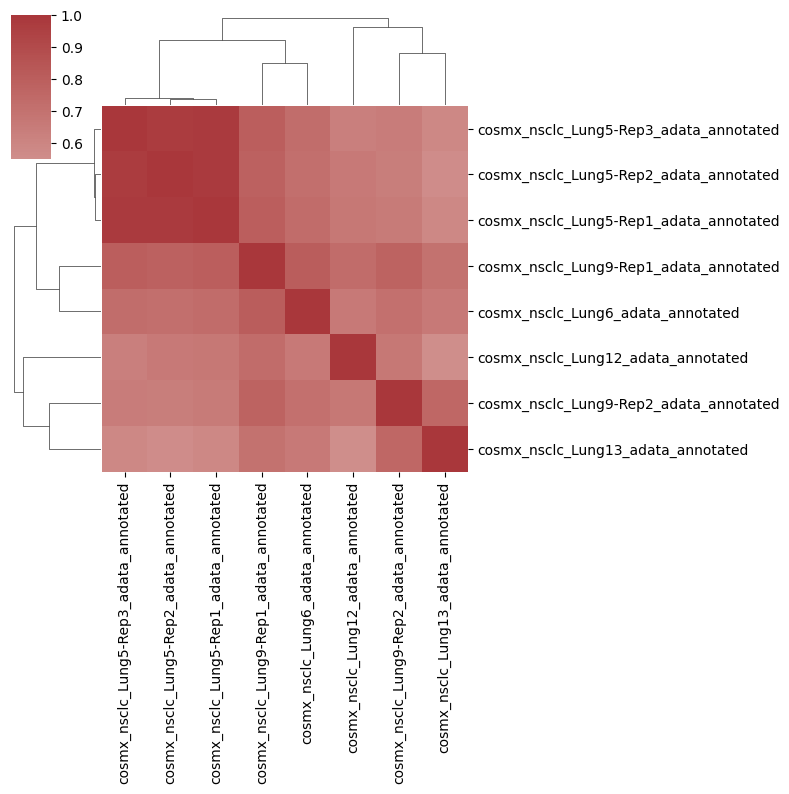

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.clustermap(
    slice_similarity.astype(float),
    cmap="vlag",
    center=0,
    figsize=(8,8),
)

plt.show()

In [22]:
sim = slice_similarity.astype(float)

candidate_scores = pd.DataFrame({
    "mean_similarity": sim.apply(lambda x: x.drop(x.name).mean(), axis=1),
    "median_similarity": sim.apply(lambda x: x.drop(x.name).median(), axis=1),
    "min_similarity": sim.apply(lambda x: x.drop(x.name).min(), axis=1),
    "q10_similarity": sim.apply(lambda x: x.drop(x.name).quantile(0.10), axis=1),
})

candidate_scores.sort_values("median_similarity", ascending=False)

,mean_similarity,median_similarity,min_similarity,q10_similarity
cosmx_nsclc_Lung9-Rep1_adata_annotated,0.772900,0.788037,0.703452,0.720938
cosmx_nsclc_Lung5-Rep1_adata_annotated,0.769804,0.727810,0.579182,0.621961
cosmx_nsclc_Lung5-Rep3_adata_annotated,0.760494,0.721086,0.579840,0.609355
cosmx_nsclc_Lung5-Rep2_adata_annotated,0.757939,0.716821,0.556040,0.603197
cosmx_nsclc_Lung6_adata_annotated,0.715883,0.716821,0.661790,0.663562
cosmx_nsclc_Lung9-Rep2_adata_annotated,0.690960,0.669464,0.634636,0.639766
cosmx_nsclc_Lung12_adata_annotated,0.652959,0.661790,0.548650,0.596879
cosmx_nsclc_Lung13_adata_annotated,0.626601,0.579840,0.548650,0.553084
